# 03 · Feature mapping (A ↔ S)

**Owner:** Sukhraj · **Phase 3** of the StayScope pipeline

The augmentation study (notebook 04) borrows behavioural features from **dataset S** (243,787 customers, the donor)
for customers of **dataset A** (5,000 customers) whose engagement columns have been removed (`A_hard`). To find
"similar" S customers, both datasets must describe customers with the **same columns and the same labels**.

This notebook:
1. lists the five concepts A and S share, and how differently they are coded;
2. **harmonizes** them into five common columns (`plan_h`, `device_h`, `genre_h`, `payment_h`, `gender_h`);
3. checks whether the shared columns *mean* the same thing in both datasets (category shares, churn rates);
4. uses **association heatmaps** to see what the shared columns can tell us about S's behaviour;
5. **chooses the transfer features**: the S columns that will be copied to A in notebook 04.

The logic lives in `src/churn/features.py`; this notebook runs it and explains the decisions.

## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from churn import config, data, eda, features as F, preprocessing as pp
from churn.plotting import CHURN, DIVERGING, NEUTRAL, RETAINED, savefig, set_style

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
TARGET, ID = config.TARGET, config.ID_COL
DATASET_COLORS = {"A": "#F5A524", "S": "#7C9CF5"}

a, s = data.load_clean_a(), data.load_clean_s()
print(f"A: {a.shape}, S: {s.shape}")

A: (5000, 12), S: (243787, 20)


## 2. The shared concepts, as coded in each dataset

Five concepts appear in both datasets. Only `subscription_type` uses identical labels.

In [2]:
shared_raw = ["subscription_type", "device", "favorite_genre", "payment_method", "gender"]
raw = pd.DataFrame({
    "A labels": [", ".join(sorted(a[c].unique())) for c in shared_raw],
    "S labels": [", ".join(sorted(s[c].unique())) for c in shared_raw],
    "labels in both": [", ".join(sorted(set(a[c]) & set(s[c]))) or "none" for c in shared_raw],
}, index=shared_raw)
raw

,A labels,S labels,labels in both
subscription_type,"Basic, Premium, Standard","Basic, Premium, Standard","Basic, Premium, Standard"
device,"Desktop, Laptop, Mobile, TV, Tablet","Computer, Mobile, TV, Tablet","Mobile, TV, Tablet"
favorite_genre,"Action, Comedy, Documentary, Drama, Horror, Ro...","Action, Comedy, Drama, Fantasy, Sci-Fi","Action, Comedy, Drama, Sci-Fi"
payment_method,"Credit Card, Crypto, Debit Card, Gift Card, Pa...","Bank transfer, Credit card, Electronic check, ...",none
gender,"Female, Male, Other","Female, Male","Female, Male"


Two further columns look shared but are **not** used:

* **`monthly_fee` (A) vs `monthly_charges` (S):** A's fee is a fixed price per plan (8.99 / 13.99 / 17.99), while
  S's charge is continuous (4.99–19.99) and independent of the plan (notebook 01). They measure different things,
  and A's fee was already dropped in cleaning because it duplicates the plan.
* **`age`, `region`, `number_of_profiles` (A only)** and **`content_type`, the Yes/No settings (S only)** have no
  counterpart on the other side.

## 3. Harmonization decisions

| Concept | Rule | Why |
|---|---|---|
| Plan | kept as is | same labels |
| Device | A's *Laptop* and *Desktop* → *Computer* | S only records "Computer" |
| Genre | Action, Comedy, Drama, Sci-Fi kept; A's Horror/Romance/Documentary and S's Fantasy → *Other* | only 4 genres exist in both |
| Payment | grouped by *how* the customer pays: **card** (credit/debit), **digital** (PayPal, crypto, e-check, bank transfer), **manual** (gift card, mailed check) | only "credit card" exists in both, so exact labels cannot match |
| Gender | Male / Female kept, A's *Other* kept as *Other* | S has no third category; these A customers will have no exact match |

The full label-by-label table (also used by the app):

In [3]:
F.mapping_table()

,feature,harmonized,raw_label,harmonized_label
0,device,device_h,TV,TV
1,device,device_h,Mobile,Mobile
2,device,device_h,Tablet,Tablet
3,device,device_h,Laptop,Computer
4,device,device_h,Desktop,Computer
5,device,device_h,Computer,Computer
6,payment_method,payment_h,Credit Card,card
7,payment_method,payment_h,Debit Card,card
8,payment_method,payment_h,PayPal,digital
9,payment_method,payment_h,Crypto,digital


In [4]:
a_h, s_h = F.harmonize(a, s)
a_h[[ID, *shared_raw, *F.COMMON_FEATURES]].head()

,customer_id,subscription_type,device,favorite_genre,payment_method,gender,plan_h,device_h,genre_h,payment_h,gender_h
0,a9b75100-82a8-427a-a208-72f24052884a,Basic,TV,Action,Gift Card,Other,Basic,TV,Action,manual,Other
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,Standard,Mobile,Sci-Fi,Gift Card,Other,Standard,Mobile,Sci-Fi,manual,Other
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,Standard,TV,Drama,Crypto,Female,Standard,TV,Drama,digital,Female
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,Premium,TV,Horror,Crypto,Other,Premium,TV,Other,digital,Other
4,4e265c34-103a-4dbb-9553-76c9aa47e946,Standard,Mobile,Action,Crypto,Other,Standard,Mobile,Action,digital,Other


## 4. Do the harmonized categories have similar shares?

If one side had a category the other lacks, or very different proportions, matching would be lopsided.

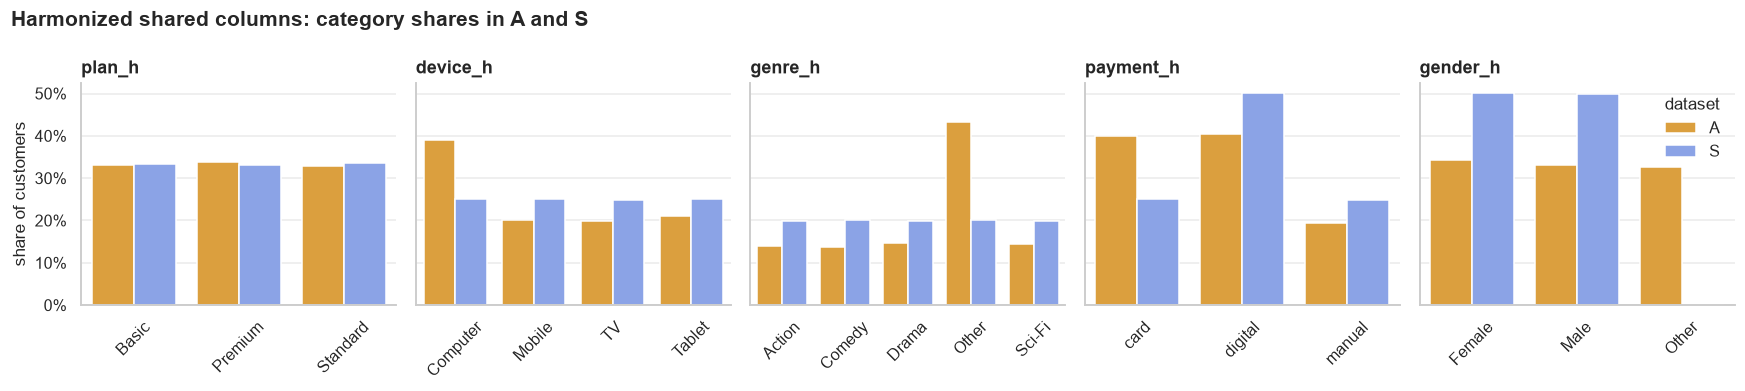

In [5]:
shares = F.category_shares(a_h, s_h)
fig, axes = plt.subplots(1, len(F.COMMON_FEATURES), figsize=(16, 3.6), sharey=True)
for ax, feat in zip(axes, F.COMMON_FEATURES):
    d = shares[shares["feature"] == feat].melt(id_vars=["feature", "category"], var_name="dataset", value_name="share")
    sns.barplot(d, x="category", y="share", hue="dataset", palette=DATASET_COLORS, ax=ax)
    ax.set_title(feat)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    if ax is not axes[-1]:
        ax.get_legend().remove()
axes[0].set_ylabel("share of customers")
fig.suptitle("Harmonized shared columns: category shares in A and S", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "03_category_shares")

In [6]:
shares.assign(diff=lambda d: d["A"] - d["S"]).sort_values("diff", key=abs, ascending=False).head(6)

dataset,feature,category,A,S,diff
6,gender_h,Other,0.327,0.000,0.327
10,genre_h,Other,0.433,0.201,0.233
5,gender_h,Male,0.331,0.500,-0.169
4,gender_h,Female,0.342,0.500,-0.158
12,payment_h,card,0.401,0.250,0.151
0,device_h,Computer,0.391,0.251,0.140


The shares line up well. Every category of a shared column is roughly uniform in both datasets. The two exceptions
come straight from the harmonization rules: **genre "Other"** holds 3 of A's 7 genres (≈43%) but only S's Fantasy
(≈20%), and **gender "Other"** (≈33% of A) does not exist in S.

## 5. Do the shared columns *mean* the same thing in both datasets?

If, say, Basic-plan customers churn most in A, a shared meaning would make them churn most in S too.

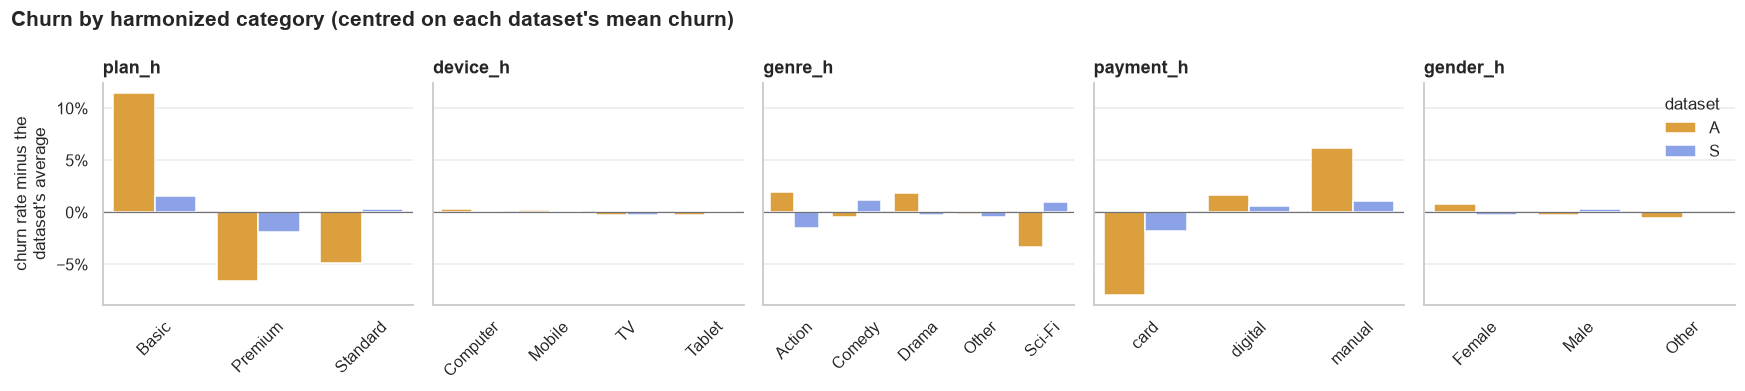

In [7]:
cb = F.churn_by_harmonized(a_h, s_h)
fig, axes = plt.subplots(1, len(F.COMMON_FEATURES), figsize=(16, 3.6), sharey=True)
for ax, feat in zip(axes, F.COMMON_FEATURES):
    d = cb[cb["feature"] == feat].copy()
    base = d.groupby("dataset")["churn_rate"].transform(lambda x: x.mean())
    d["vs_dataset_mean"] = d["churn_rate"] - base  # centre each dataset on its own average (A 50%, S 18%)
    sns.barplot(d, x="category", y="vs_dataset_mean", hue="dataset", palette=DATASET_COLORS, ax=ax)
    ax.axhline(0, color=NEUTRAL, lw=0.8)
    ax.set_title(feat)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    if ax is not axes[-1]:
        ax.get_legend().remove()
axes[0].set_ylabel("churn rate minus the\ndataset's average")
fig.suptitle("Churn by harmonized category (centred on each dataset's mean churn)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "03_churn_by_shared")

In [8]:
pivot = cb.pivot_table(index=["feature", "category"], columns="dataset", values="churn_rate")
corr = {f: pivot.loc[f, "A"].corr(pivot.loc[f, "S"], method="spearman")
        for f in F.COMMON_FEATURES if pivot.loc[f].dropna().shape[0] > 2}
display(pivot.style.format("{:.1%}"))
pd.Series(corr, name="rank agreement A vs S (Spearman, over categories)")

plan_h       1.000
device_h     0.400
genre_h     -0.800
payment_h    1.000
Name: rank agreement A vs S (Spearman, over categories), dtype: float64

The **direction** is shared, but the **size** is not:

* **Plan:** Basic churns most in both datasets. In A the gap is large (62% vs 44–45%); in S it is small (20% vs 16–18%).
* **Payment group:** churn rises from *card* to *digital* to *manual* in both (A: 44% → 53% → 58%, S: 16% → 19% → 19%),
  which supports the card / digital / manual grouping.
* **Device, gender:** flat in both. **Genre:** small differences that do not agree (rank agreement −0.8).

So the harmonization is sensible: where a shared column carries signal, it points the same way in both datasets.
But in S that signal is weak, so the shared columns are a poor basis for finding customers who behave alike.

## 6. Association heatmaps

**(a) Shared columns among themselves.** Are the shared columns independent of each other inside each dataset?
(bias-corrected Cramér's V; 0 = independent)

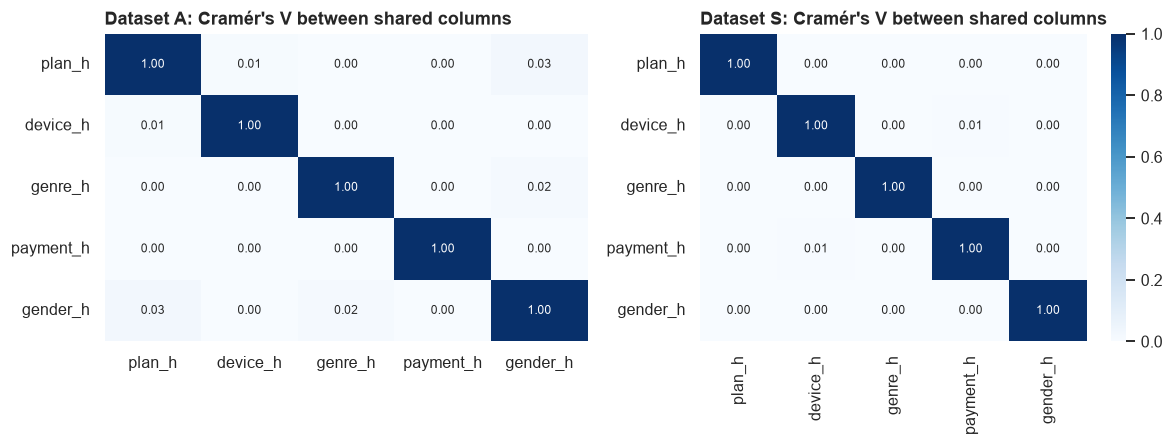

In [9]:
def cramers_matrix(df, cols):
    return pd.DataFrame([[eda.cramers_v(df[r], df[c]) if r != c else 1.0 for c in cols] for r in cols],
                        index=cols, columns=cols)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, df) in zip(axes, [("A", a_h), ("S", s_h)]):
    sns.heatmap(cramers_matrix(df, F.COMMON_FEATURES), annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Blues",
                cbar=ax is axes[-1], ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Dataset {name}: Cramér's V between shared columns")
fig.tight_layout()
savefig(fig, "03_shared_associations")

**(b) Shared columns → S's behaviour.** This is the question that matters for transfer: does knowing a customer's
plan, device, genre, payment group and gender tell us anything about their viewing, tenure or support behaviour?
Correlation ratio η: the share of a numeric column's spread explained by a category (0 = nothing, 1 = everything).

largest η: 0.0061


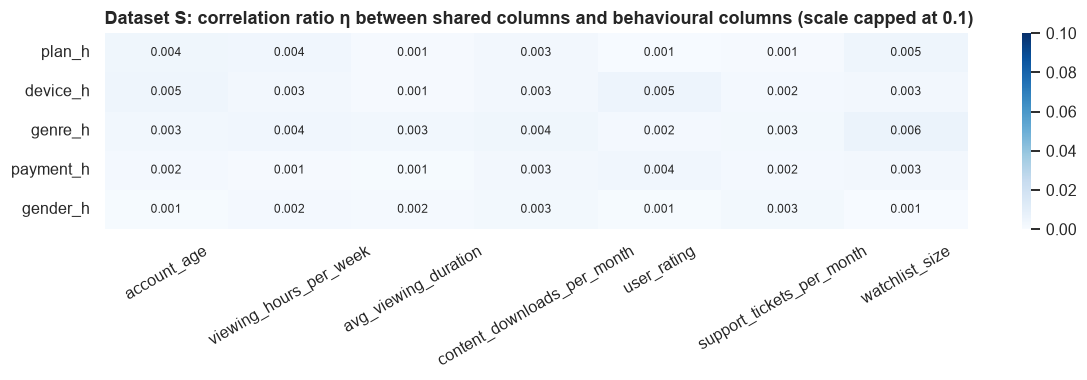

In [10]:
eta = F.shared_vs_behaviour(s_h)
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(eta, annot=True, fmt=".3f", vmin=0, vmax=0.1, cmap="Blues", ax=ax, annot_kws={"size": 8})
ax.set_title("Dataset S: correlation ratio η between shared columns and behavioural columns (scale capped at 0.1)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
savefig(fig, "03_shared_vs_behaviour")
print(f"largest η: {eta.max().max():.4f}")

Every cell is essentially **0**: the shared columns explain none of S's behaviour (S's columns were generated
independently, notebook 01). Notebook 04 confirms this with a cross-validated model (the pre-check).

## 7. Choosing the transfer features

Candidates are S's behavioural columns that A does not have. `monthly_charges` is excluded (pricing, not behaviour,
and A's fee means something else). A candidate is **transferred** if it carries churn signal in S
(|Spearman ρ| ≥ 0.05): copying a column that does not predict churn even in S cannot help in A.

In [11]:
assoc = eda.target_association(s, F.TRANSFER_CANDIDATES, [], TARGET).set_index("feature")
choice = assoc[["value"]].rename(columns={"value": "spearman_rho_with_churn_in_S"})
choice["transfer"] = choice["spearman_rho_with_churn_in_S"].abs() >= F.MIN_CHURN_ASSOCIATION
assert sorted(choice.index[choice["transfer"]]) == sorted(F.TRANSFER_FEATURES), "update features.TRANSFER_FEATURES"
choice

,spearman_rho_with_churn_in_S,transfer
feature,,
account_age,-0.198,True
avg_viewing_duration,-0.147,True
content_downloads_per_month,-0.130,True
viewing_hours_per_week,-0.129,True
support_tickets_per_month,0.084,True
user_rating,0.022,False
watchlist_size,0.022,False


In [12]:
other = eda.target_association(s, pp.S_FEATURES_BINARY + ["monthly_charges"], ["content_type"], TARGET)
other[["feature", "measure", "value"]]

,feature,measure,value
0,monthly_charges,spearman,0.100
1,content_type,cramers_v,0.013
2,subtitles_enabled,spearman,-0.012
3,parental_control,spearman,-0.006
4,multi_device_access,spearman,-0.001
5,paperless_billing,spearman,-0.001


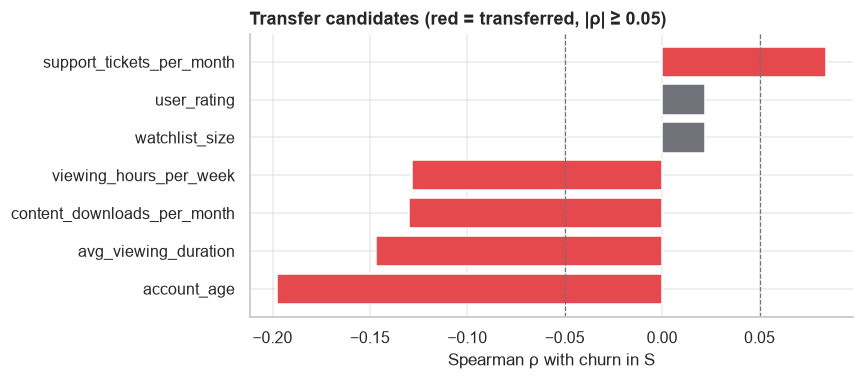

In [13]:
d = choice.reset_index().sort_values("spearman_rho_with_churn_in_S")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(d["feature"], d["spearman_rho_with_churn_in_S"],
        color=[CHURN if t else NEUTRAL for t in d["transfer"]])
for x in (-F.MIN_CHURN_ASSOCIATION, F.MIN_CHURN_ASSOCIATION):
    ax.axvline(x, color=NEUTRAL, ls="--", lw=0.8)
ax.set_xlabel("Spearman ρ with churn in S")
ax.set_title("Transfer candidates (red = transferred, |ρ| ≥ 0.05)")
fig.tight_layout()
savefig(fig, "03_transfer_selection")

The categorical and Yes/No columns of S (`content_type`, `paperless_billing`, …) are not transferred: their churn
association is below 0.02. The transfer code still supports categorical columns (similarity-weighted majority), so
they can be added later if needed.

**Transfer features:** `account_age`, `avg_viewing_duration`, `content_downloads_per_month`,
`viewing_hours_per_week`, `support_tickets_per_month` (`features.TRANSFER_FEATURES`).

## 8. Key findings

1. **Five concepts are shared**, but only the plan has identical labels. After harmonization (devices merged into
   *Computer*, 4 shared genres + *Other*, payment grouped into card / digital / manual), all five line up, and their
   category shares are similar in A and S. The exceptions are genre *Other* and A's gender *Other*, which S lacks.
2. **Same direction, very different strength.** Basic plan and non-card payment raise churn in both datasets, so
   the mapping is consistent. But the effect is large in A (Basic 62%, *manual* payment 58%) and small in S
   (Basic 20% vs 18% overall). Device, genre and gender carry no churn signal in either.
3. **The shared columns say nothing about behaviour in S.** η ≈ 0 between every shared column and every behavioural
   column. So customers who look alike on the shared columns do not behave alike. This predicts that
   similarity-based transfer will give A noise, not signal. Notebook 04 tests that prediction.
4. **Transfer features:** the five S behavioural columns with real churn signal in S (|ρ| ≥ 0.05): account age,
   average viewing duration, downloads, weekly viewing hours and support tickets.
5. **Matching uses the five harmonized columns only.** `churned` is never part of the matching vector.